In [88]:
import numpy as np
import matplotlib.pyplot as plt

import os
from statsmodels.stats.weightstats import DescrStatsW

In [89]:
location_type_info = [
    "on a helix facing the membrane core",
    "on a helix facing water or headgroups",
    "on a helix N terminal with no helix carbonyl to hydrogen bond with (variable solvation)",
    "on a loop (all of these are in water)"
]

#copy command:
#in: /home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation
#scp -r jborowsky@x01.ucsf.edu:/media/X01Raid01/Data_Backup/home/jborowsky/aac1-ucp1-aa-and-threonine/long-aac1-ucp1-processing/thr_rotamers/ .

In [ ]:
def plot_rotamers_all_sites(mean_std_rotamer_freqs, n_sites, n_rotamers, protein):
    bar_width = 0.2
    gap_width = 0.2

    x = -bar_width*1.5
    
    for rotamer in range(n_rotamers):
        for site in range(n_sites):

            plt.bar((x), (mean_std_rotamer_freqs[0,site,rotamer]), yerr=(mean_std_rotamer_freqs[1,site,rotamer]), width=bar_width, color = f"C{site}")

            x += bar_width
        x += gap_width

    plt.xticks([0,1,2], ('180', '-60', '60'))
    plt.xlim(-2*bar_width, (n_rotamers-1)*gap_width + bar_width*(n_sites*n_rotamers-2))
    plt.ylim(0,1)

    plt.ylabel("Frequency")
    plt.xlabel("Sidechain dihedral angle (degrees)")
    plt.legend(["intrahelical membrane+interior", "intrahelical aqueous", "helix N terminus (variable solvation)", "loop (aqueous)"])

    plt.show()

In [107]:
def plot_rotamers_3_sites(mean_std_rotamer_freqs, n_sites, n_rotamers, protein):
    bar_width = 0.25
    gap_width = 0.25

    x = -bar_width
    
    for rotamer in [1,2,0]:
        for site, color in zip([0,1,3], ["C0","C1","C2"]):

            plt.bar((x), (mean_std_rotamer_freqs[0,site,rotamer]), yerr=(mean_std_rotamer_freqs[1,site,rotamer]), width=bar_width, color = color)

            x += bar_width
        x += gap_width

    plt.xticks([0,1,2], ('-60', '60', '180'))
    offset = 1.5
    plt.xlim(-offset*bar_width, (n_rotamers-1)*gap_width + bar_width*(3*n_rotamers-offset))
    plt.ylim(0,1)

    plt.ylabel("Frequency")
    plt.xlabel("Sidechain dihedral angle (degrees)")
    plt.legend(["intrahelical membrane+interior", "intrahelical aqueous", "loop (aqueous)"])

    plt.title(f"{protein.upper()} rotamer frequency")

    plt.show()

[[[1.69978653e-02 9.24284883e-01 5.87172521e-02]
  [6.68115661e-02 7.50597063e-01 1.82591371e-01]
  [8.46109063e-04 5.03314574e-01 4.95839317e-01]
  [4.13157384e-02 1.50652047e-01 8.08032214e-01]]

 [[2.97242276e-02 1.16923473e-01 9.28690872e-02]
  [5.63662180e-02 2.16810134e-01 1.69533290e-01]
  [3.87570910e-04 1.41483812e-01 1.41818108e-01]
  [2.25958742e-02 1.15900218e-01 1.11832503e-01]]]
these should all be 1:
[1. 1. 1. 1.]


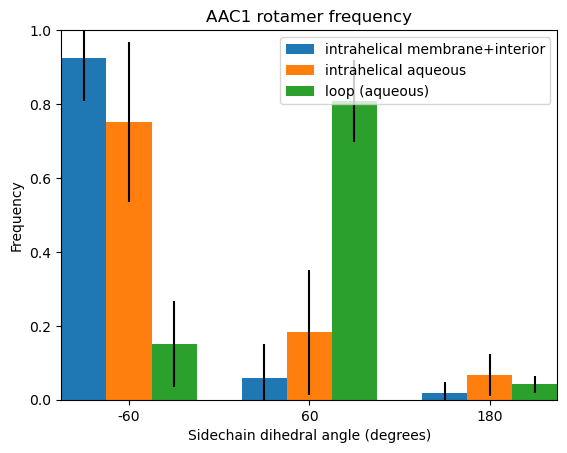

[[[0.00061235 0.56733985 0.43204781]
  [0.06176391 0.55453751 0.38369859]
  [0.03960942 0.57202607 0.38836451]
  [0.32667735 0.11593087 0.55739178]]

 [[0.00142858 0.40720005 0.40707843]
  [0.08359249 0.35665606 0.35170283]
  [0.06076981 0.36011498 0.35766437]
  [0.2526334  0.05640506 0.27562477]]]
these should all be 1:
[1. 1. 1. 1.]


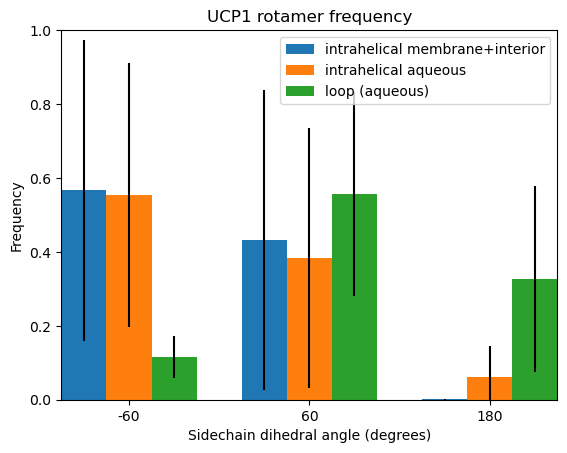

In [108]:
inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/thr_rotamers"

servers = ["wynton", "degrabo"]
proteins = ["aac1", "ucp1"]


#loop over servers, proteins, and parallel runs
for protein in proteins:

    #--------------------------------------------------------------------------
    #                  load rotamer data for each run

    rotamer_freqs_all = [] #frequency of each rotamer for each residue
    n_frames_all = [] #number of frames in run

    for server in servers:    
        for run in range(1,5):

            rotamer_data = []

            #not all servers have the same number of parallel simulations
            if run > 2 and server == "degrabo": continue

            for seg in range(1,20):

                #load data if it exists
                datafile = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-thr-rotamer-counts.npy"
                if not os.path.exists(datafile): break
                data = np.load(datafile)
                
                rotamer_data.append(data)

            #skip runs with no data
            if len(rotamer_data) > 0:

                #add up counts from all segments to get total counts for each run
                rotamer_counts_bysegment = np.stack(rotamer_data, axis=-1)
                rotamer_counts_total = np.sum(rotamer_counts_bysegment, axis=-1)

                #count frames in the run
                n_frames = np.sum(rotamer_counts_total[0][0], axis = 0)
                #halve the frame counts for the two runs with frames saved twice as often
                if run > 2:
                    n_frames_eff = n_frames/2 
                else:
                    n_frames_eff = n_frames
                n_frames_all.append(n_frames_eff)

                #calculate frequency of each rotamer
                rotamer_freqs = rotamer_counts_total/n_frames
                rotamer_freqs_all.append(rotamer_freqs)

    #rotamer_freqs_all has shape [n_sites, max_n_resis_per_site, n_rotamers, n_trajectories]
    rotamer_freqs_all = np.stack(rotamer_freqs_all, axis=-1)


    #--------------------------------------------------------------------------
    #                  calculate rotamer frequency at each site

    n_sites = 4 #this is really the number of kinds of site
    n_rotamers = 3 #this is a variable for code readability, not because I have any intention of varying it

    #average frequency of each site-rotamer pair
    mean_std_rotamer_freqs = np.zeros((2, n_sites, n_rotamers)) 

    for site in range(n_sites):
        #rotamer_freqs_s has shape [n_resis_in_current_site, n_rotamers, n_trajectories]
        #pull out rotamer data for the current site (i.e. helices facing the membrane core)
        rotamer_freqs_s = rotamer_freqs_all[site]
        #find array indices corresponding to actual residues, using trajectory 0 arbitrarily
        extant_residues = np.where(np.sum(rotamer_freqs_s[:,:,0], axis = 1)>0)
        rotamer_freqs_s = rotamer_freqs_s[extant_residues]

        #weight the data from each residue in each trajectory by the number of frames in that trajectory
        trj_weights = [n_frames_all[trji] for resi in range(rotamer_freqs_s.shape[0]) for trji in range(rotamer_freqs_s.shape[2])]
        
        for rot in range(n_rotamers):
            #rotamer_freqs_s[:,rot] has shape [n_resis_in_current_site, n_trajectories]
            rotamer_freqs_sr = rotamer_freqs_s[:,rot].flatten()

            #calculate mean and standard deviation weighted by trajectory length
            mean_std_rotamer_freqs[0, site, rot] = np.average(rotamer_freqs_sr, weights=trj_weights)
            mean_std_rotamer_freqs[1, site, rot] = DescrStatsW(rotamer_freqs_sr, weights=trj_weights, ddof=1).std
            #mean_std_rotamer_freqs[1, site, rot] = np.std(rotamer_freqs_sr) #unweighted

    print(mean_std_rotamer_freqs)

    #check normalization; all of these should be 1
    print("these should all be 1:")
    print(np.sum(mean_std_rotamer_freqs[0], axis=1))


    #--------------------------------------------------------------------------
    #                               plot results

#    plot_rotamers_all_sites(mean_std_rotamer_freqs, n_sites, n_rotamers)

    plot_rotamers_3_sites(mean_std_rotamer_freqs, n_sites, n_rotamers, protein)

            

